# WP12 — Gerçek S01-R1 denemesinin bağımsız incelemesi

**Sonuç: teknik üretim tamamlandı; kaynaklı Türkçe açıklama kabul edilemedi.** HTTP200/stop ve geçerli JSON Schema, kaynak sadakati veya uygulama sözleşmesi başarısı değildir. Aşağıdaki çıktılar gerçek kullanıcı run'ından gelir. Bu notebook yalnız okur; ağ/LLM/optimizer/tekrar yoktur. İnsan onayı hâlâ bekliyor; otomatik yayın/19×3/WP13 yok.

In [1]:
from pathlib import Path
import sys,json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():ROOT=ROOT.parent
Q=ROOT/'reports/qa/WP12/experimental_low_memory_S01_R1_review_v1'
RUN=ROOT/'reports/qa/WP12/experimental_low_memory_user_runs_v1/20261108_065325_050e95866a054763b9ac7d5551e1f8f5'
F=ROOT/'reports/figures/WP12/experimental_low_memory_S01_R1_review_v1'
def read(p):return json.loads(Path(p).read_text(encoding='utf-8-sig'))
r=read(Q/'independent_audit.json')
pd.set_option('display.max_colwidth',600);pd.set_option('display.max_rows',50)

display(pd.DataFrame([r['technical']]).T.rename(columns={0:'doğrulanmış_kayıt'}))
display(pd.DataFrame([r['source']]).T.rename(columns={0:'kaynak_bütünlüğü'}))


,doğrulanmış_kayıt
model_produced_nonempty_response,True
HTTP_status,200
done,True
done_reason,stop
prompt_tokens,919
prompt_cached_tokens,0
output_tokens,188
output_budget,384
prompt_limit,1536
context,2048


,kaynak_bütünlüğü
raw_files,17
manifest_entries,16
all_raw_hashes_valid,True
request_and_frozen_context_equal,True
API_digest,sha256:97558784bdc9175075a72655bf360b15da17df6b3b9e5182af9f8c0c8e58ba7c
wrapper_and_source_manifest_independently_valid,True
case_policy_hash_valid,True
script_hash_valid,True
recorded_attempts,1
new_downloads_recorded,0


**Yorum:** Onaylı API9755… ve yerel wrapper313f… farklı kimlik nesneleridir; ayrı hash ve doğru manifest bağlantısıyla doğrulandı.17 ham dosya/16 manifest girdisi korundu.919 prompt,0 cached prompt ve188 output token; truncation/length stop/timeout kaydı yok.8,708s sunucu total;14,233s istemci bloğu Python incelemesini de içerir. Bunlar aynı süre tanımı değildir.

## Gerçek yanıt — aynen

In [2]:

response=read(RUN/'source_response_raw.json')
print(response['message']['content'])
print('\nexplanation_tr alanı AYNEN:')
candidate=json.loads(response['message']['content']);print(candidate['items'][0]['explanation_tr'])
print('\nİNCELEYENİN TÜRKÇE ÇEVİRİSİ; MODEL ÇIKTISI DEĞİLDİR:')
print(r['semantic']['reviewer_Turkish_translation_NOT_MODEL_OUTPUT'])


{
  "schema_version": "WP12-local-llm-candidate-v1",
  "status": "refused",
  "refusal_code": "IMAGE_TEXT_UNAVAILABLE",
  "items": [
    {
      "explanation_tr": "The provided text does not contain any information about the product's form or formulation.",
    	"source_scope": "product_identity",
    "statement_kind": "formulation",
    "evidence_ids": [
      "quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe"
    ]
  }
]
}

explanation_tr alanı AYNEN:
The provided text does not contain any information about the product's form or formulation.

İNCELEYENİN TÜRKÇE ÇEVİRİSİ; MODEL ÇIKTISI DEĞİLDİR:
Sağlanan metin, ürünün şekli veya formülasyonu hakkında herhangi bir bilgi içermiyor.


**Yorum:** Model Türkçe açıklama üretmedi; `explanation_tr` İngilizcedir. Rapordaki Türkçe çeviri inceleyenin çevirisidir ve yeni LLM çıktısı gibi sunulmaz. “Formülasyon bilgisi yok” iddiası kaynakla çelişir. IMAGE_TEXT_UNAVAILABLE gerekçesi bu iki metin alıntısı için desteklenmez.

## JSON Schema, uygulama sözleşmesi ve kaynak anlamı

In [3]:

display(pd.DataFrame([{'kontrol':'JSON sözdizimi','sonuç':r['structural']['JSON_syntax_valid']},
 {'kontrol':'V1 JSON Schema','sonuç':r['structural']['v1_JSON_Schema_valid']},
 {'kontrol':'Vaka JSON Schema','sonuç':r['structural']['case_JSON_Schema_valid']},
 {'kontrol':'Uygulama sözleşmesi','sonuç':r['structural']['application_contract_valid']},
 {'kontrol':'Kaynak sadakati (Codex incelemesi)','sonuç':r['semantic']['agent_assessment']},
 {'kontrol':'İnsan onayı','sonuç':r['semantic']['human_semantic_review']}]))
display(pd.DataFrame(r['structural']['item_checks']))
display(pd.read_csv(Q/'source_claim_comparison.csv'))


,kontrol,sonuç
0,JSON sözdizimi,True
1,V1 JSON Schema,True
2,Vaka JSON Schema,True
3,Uygulama sözleşmesi,False
4,Kaynak sadakati (Codex incelemesi),SOURCE_FAITHFULNESS_FAIL
5,İnsan onayı,PENDING


,item_index,selected_real_quote,source_scope_matches_primary,statement_kind_matches_primary,output_kind,cited_quote_kind,cited_quote_ids
0,0,True,True,False,formulation,identity,[quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe]


,topic,source_fact,assessment_tr,status
0,ürün,Page1 names Erythromycin Tablets BP 250 mg,Ürün adı/doz açıklanmamış.,OMITTED
1,etkin_madde,Page1: contains active ingredient erythromycin; macrolide antibiotics,Etkin madde ve ilaç sınıfı aktarılmamış.,OMITTED
2,formülasyon,"Page6: red coloured, round, biconvex, enteric-coated tablets",Formülasyon bilgisi yok iddiası açık kaynakla çelişiyor.,CONTRADICTED
3,ambalaj,Page6: blister28/56/84/100; containers21/100/250/500/1000,Ambalaj bilgileri aktarılmamış.,OMITTED
4,belirsizlik,Selected quotes have no image-only or unknown-text qualifier,IMAGE_TEXT_UNAVAILABLE desteklenmiyor; bu sayfalar metin katmanından okunabilir.,UNSUPPORTED_REFUSAL
5,atıf,Cited page1 quote is identity; page6 formulation quote was supplied but not cited,Gerçek quote-ID seçilmiş ancak formulation amacı identity alıntısına bağlanmış.,MISATTRIBUTED
6,dil,Frozen prompt requests Turkish explanation,explanation_tr İngilizce; gerçek Türkçe açıklama yok.,WRONG_LANGUAGE
7,eşdeğerlik,Parent/product equivalence must not be invented,Yeni ana ilaç/ürün eşdeğerliği iddiası yok; bu durum yanlış reti başarılı kılmaz.,NO_EQUIVALENCE_CLAIM
8,yasak_çıktı,"No model score, SHAP, delta-z, ADR or MedDRA generation",Bu yanıtta yeni skor/etiket/yan etki üretilmemiş.,NO_FORBIDDEN_GENERATION


**Yorum:** Mevcut şema `refused` ise boş items koşulunu JSON Schema içinde şartlı tanımlamıyor; dolayısıyla Schema geçiyor. Değişmeyen uygulama doğrulayıcısı `invalid refusal` ile durduruyor. Bağımsız item kontrolü ayrıca formulation amacının identity alıntısına bağlandığını gösterdi; source_scope doğru, ID gerçek olsa bile bu amaç uyumu doğru değildir. Eski şema/validator/yanıt düzeltilmedi.

## Özgün fiziksel sayfalar ve birebir alıntılar

,page,char_start,char_end,quote_id,quote,source_span_matches_original_PDF
0,1,1028,1281,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n",True
1,6,987,1271,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n",True


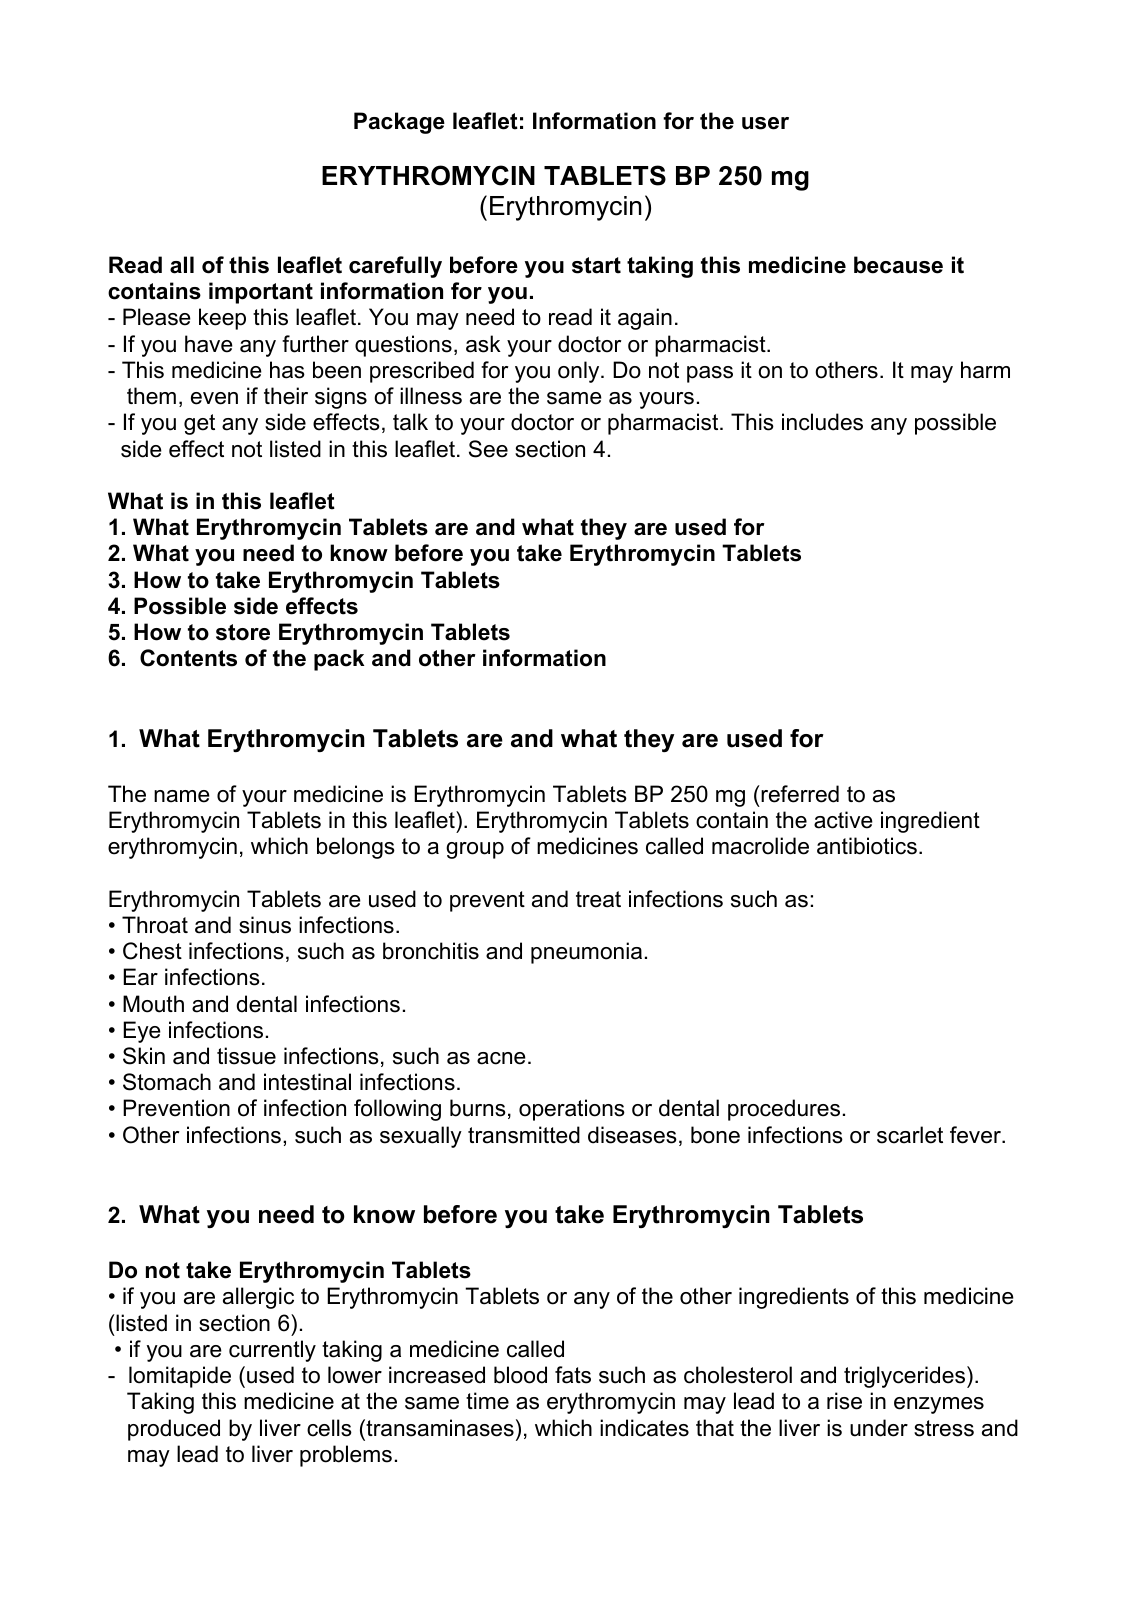

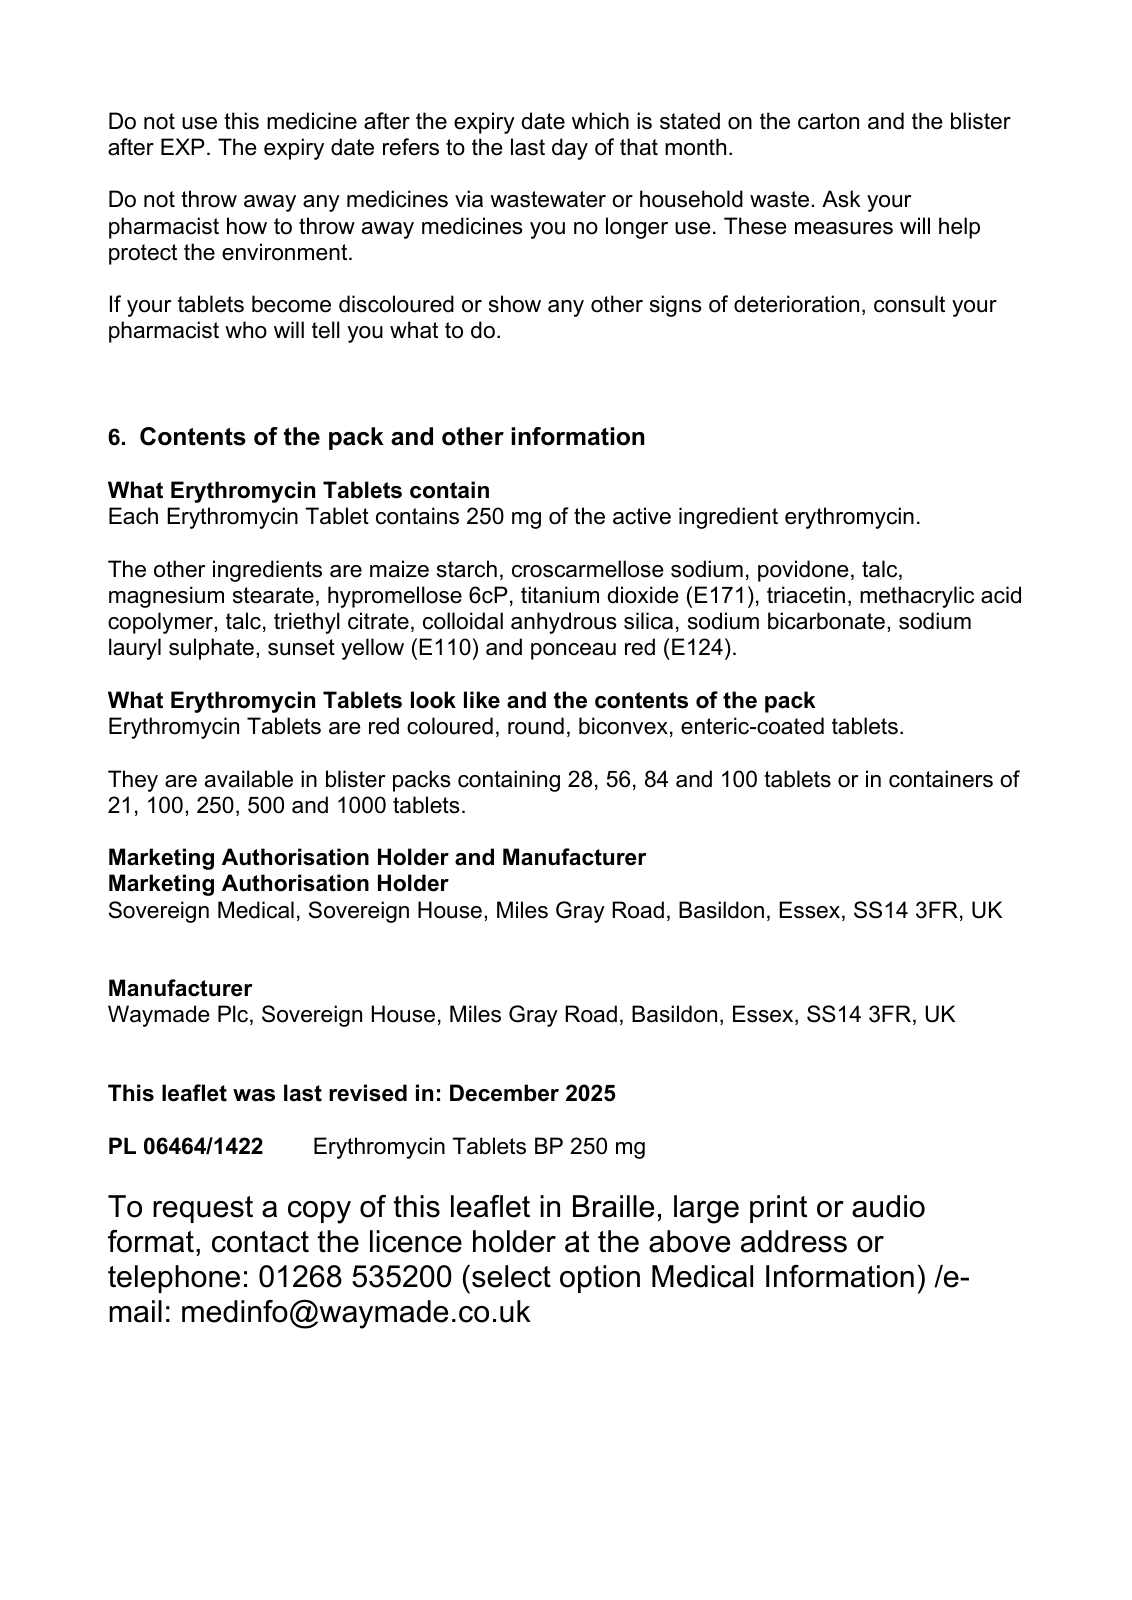

In [4]:

sources=read(Q/'original_PDF_source_checks.json')
display(pd.DataFrame(sources)[['page','char_start','char_end','quote_id','quote','source_span_matches_original_PDF']])
display(Image(filename=str(F/'original_physical_page_1.png'),width=650))
display(Image(filename=str(F/'original_physical_page_6.png'),width=650))


**Yorum:** İki tam fiziksel sayfa Poppler ile render edilip görsel olarak kontrol edildi. Mevcut PyMuPDF text yolu ile sayfa metinleri kabul edilmiş extraction'a, `[start,end)` aralıkları alıntılara ve SHA'ları ham PDF'ye eşit bulundu. Sayfa1 ürün/etkin maddeyi; sayfa6 kırmızı, yuvarlak, bikonveks, enterik kaplı tablet ve ambalajı açıkça veriyor. Tam sayfa render'ındaki diğer içerikler modele verilmiş gibi değerlendirilmez: prompt yalnız dondurulmuş iki alıntıyı içeriyordu. Model bunları aktarmadı; doğrudan çelişen bilgi-yok iddiası verdi. Seçilen alıntılarda unknown-frequency/might gibi qualifier yok; S04 belirsizlik vakası bu run ile sınanmış sayılmaz.

## Gerçek bellek örnekleri ve sınırlar

,gerçek_ölçüm
entry_RAM_GiB,1.751541
immediate_RAM_GiB,1.714378
after_RAM_GiB,1.718765
stable_sample_count,5
stable_span_seconds,4.05535
entry_gates_passed,True
runtime_sample_count,37
sampled_RAM_min_GiB,0.997353
sampled_RAM_max_GiB,1.718616
sampled_commit_min_GiB,9.461472


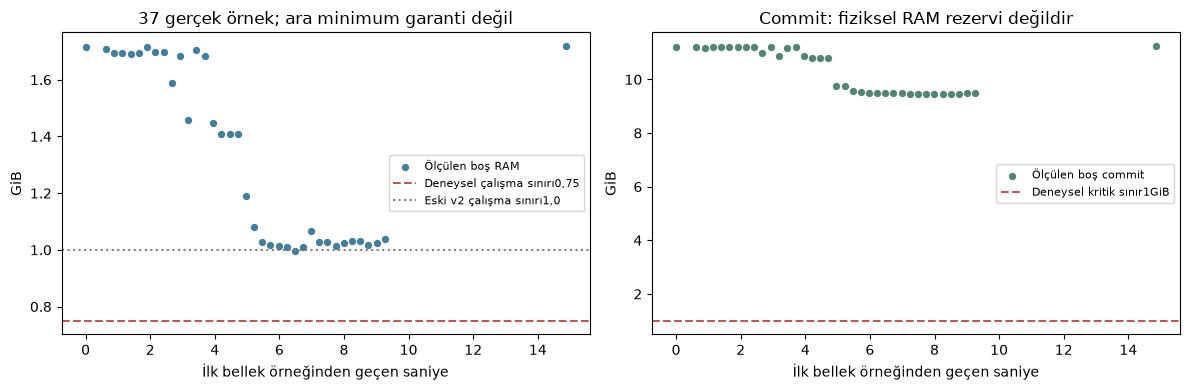

In [5]:

display(pd.DataFrame([r['memory']]).T.rename(columns={0:'gerçek_ölçüm'}))
memory=pd.read_csv(Q/'actual_runtime_memory.csv')
times=pd.to_datetime(memory['at'],utc=True);seconds=(times-times.iloc[0]).dt.total_seconds()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(seconds,memory.RAM_GiB,s=18,color='#467d98',label='Ölçülen boş RAM')
axes[0].axhline(.75,color='#b35c5c',ls='--',label='Deneysel çalışma sınırı0,75')
axes[0].axhline(1,color='gray',ls=':',label='Eski v2 çalışma sınırı1,0')
axes[0].set(xlabel='İlk bellek örneğinden geçen saniye',ylabel='GiB',title='37 gerçek örnek; ara minimum garanti değil');axes[0].legend(fontsize=8)
axes[1].scatter(seconds,memory.commit_GiB,s=18,color='#558572',label='Ölçülen boş commit')
axes[1].axhline(1,color='#b35c5c',ls='--',label='Deneysel kritik sınır1GiB')
axes[1].set(xlabel='İlk bellek örneğinden geçen saniye',ylabel='GiB',title='Commit: fiziksel RAM rezervi değildir');axes[1].legend(fontsize=8)
plt.tight_layout();plt.savefig(F/'actual_runtime_memory.png',dpi=160);plt.show()


**Yorum:** Giriş1,752GiB; istekten hemen önce1,714GiB.37 örnekte minimum0,997GiB, commit minimum9,461GiB ve OS düşük bellek0. Deneysel0,75 sınırı aşılmadı; eski1GiB uyarısı farklı politika olarak korunur ve burada geriye dönük yeniden uygulanmaz. GPU başlangıç/son3935MiB; inference sırasındaki peakUNKNOWN. Sistem baskısının örnekler arasında olmadığı veya process tepe RAM'inin ne olduğu söylenemez. Böylece tek çalışmanın teknik uygulanabilirliği gözlendi; genel güvenlik/uygulanabilirlik kanıtlanmadı. Yanlış yanıtın nedenini RAM/model boyutu/dil yeteneğine bağlamak için veri yok; UNKNOWN.

## Karar ve durma noktası

In [6]:

print((Q/'test_actual_run_review.log').read_text(encoding='utf-8-sig').split('----------------------------------------------------------------------')[-1])
display(pd.DataFrame([{'teknik_üretim':'TAMAMLANDI','uygulama_sözleşmesi':'BAŞARISIZ',
 'Codex_kaynak_incelemesi':'BAŞARISIZ','insan_onayı':'BEKLİYOR','yayımlanabilir':False,
 'yeni_inference':0,'otomatik_tekrar':False,'19×3':'BAŞLATILMADI','WP13':'BAŞLATILMADI'}]))



Ran 25 tests in 0.356s

OK



,teknik_üretim,uygulama_sözleşmesi,Codex_kaynak_incelemesi,insan_onayı,yayımlanabilir,yeni_inference,otomatik_tekrar,19×3,WP13
0,TAMAMLANDI,BAŞARISIZ,BAŞARISIZ,BEKLİYOR,False,0,False,BAŞLATILMADI,BAŞLATILMADI


**Sonraki aşama önerisi:** Bu yanıt ilk-vaka başarı kapısını geçmedi;19×3 açılmamalı. Önce kullanıcı insan incelemesi. Gerekirse daha sonraki açık kararla ayrı sürümlü şema/prompt uyumu önerisi hazırlanabilir; bu tur hiçbir yöntem/ayar/seed/timeout/eşik/ham çıktı değiştirilmedi ve yeni inference yapılmadı. Mevcut tek başarısız yanıt saklı kalır; otomatik tamir veya en iyi tekrar seçimi yoktur. B0/B1/B2, GNN, SHAP ve PPI sonuçları aynı kalır.